<a href="https://colab.research.google.com/github/Kownlage/English/blob/main/rb_tree_cluster_access_log_lab_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Cluster Access Log Lab: GPU Requests and Standard Red–Black Tree

Copy the LLRB method bodies from your own completed `dsa/maps/rb_tree_map.py`
into the 12 LLRB TODOs, reuse seven of those bodies in the Standard tree,
then write the four Standard insertion methods. Complete
**three comparison questions** and submit **exactly five images** (1–3–1).
After pasting your Lab 08 code, this notebook runs independently in Colab or
locally. Run All reports PENDING safely while either tree is unfinished.

## Workflow

1. Copy your completed Lab 08 LLRB method bodies into the 12 LLRB TODOs.
2. Reuse seven of those bodies in the Standard TODOs: `__len__`, `_is_red`,
   `_search`, `__getitem__`, `__contains__`, `__iter__`, `_replace_child`.
3. Write the four new Standard methods: `__setitem__`, `_rotate_left`, `_rotate_right`, `_fix_insert`.
4. Run the edited class cells and checks. Both trees must pass: **ALL CHECKS PASSED**.
5. Load **Two GPU requests** once and answer the three questions in sequence.
6. Submit your code, three written answers, and **exactly five images** (1 + 3 + 1).

Both classes reuse your previous work. Node/constructor scaffolds, data, checks, and
widgets are provided. Additional presets exercise other insertion cases in
the automated checks; they do not create more written questions or screenshots.

In [296]:
try:
    from google.colab import output as colab_output
except ImportError:
    pass
else:
    colab_output.enable_custom_widget_manager()
print("Setup complete. Continue from top to bottom.")

Setup complete. Continue from top to bottom.


## Cluster Access Log: students request GPUs for AI training

The university's **Atlas GPU cluster** supports AI training. A student may
submit several requests because they need more GPUs for additional training
jobs. We record each request by its submission time.

**Assumption: all request times are different. Time alone is the key.**
Times are integer seconds since midnight on one simulated day. Student names
and the Atlas cluster may repeat; neither is part of the key. The app therefore
has only two entry fields: **When** and **Student**; Atlas is filled automatically.

The three questions follow this one sequence:

| Arrival | When (key) | Student | GPU cluster | Used in |
|---|---|---|---|---|
| 1 | 09:00:10 | Alice | Atlas | Question 1 |
| 2 | 09:00:30 | Ben | Atlas | Question 1 |
| 3 | 09:00:20 | Alice | Atlas | Question 2 |
| 4 | 09:00:05 | Ben | Atlas | Question 3 |

Load **Two GPU requests** once for the first two rows. Then add the last two
rows in order. **Do not reload a preset between Questions 1, 2, and 3.**
Arrival order can differ from time order, and repeated students remain separate.

```python
key = to_seconds(when)
value = {"student": student, "cluster": "Atlas"}
```

Smaller times belong in the left subtree and larger times in the right subtree.
Rotations may change the root and parent/child positions while preserving
inorder time order. RED and BLACK describe balance, not GPU approval or priority.
The app records requests; GPU allocation and deletion are outside this lab.
The app rejects duplicate request times. Equal-key overwrite is still checked
separately as part of the generic map contract.

## Provided infrastructure

Snapshots, basic map helpers, invariant checks, and trace
wrappers are provided below. `check_standard` allows red right links and two
red children; `check_llrb` adds the left-leaning restriction. Black height
uniformly excludes NIL endpoints; tree height counts real-node levels.

In [297]:
from typing import TypeVar, Iterator, Optional
from html import escape
import math
K = TypeVar('K')
V = TypeVar('V')

def tree_snapshot(root):
    """Immutable keys/colors/shape for the renderer and trace; no live nodes."""
    seen = set()

    def copy(node):
        if node is None:
            return None
        if id(node) in seen:
            raise AssertionError('Cycle or shared child in the tree')
        seen.add(id(node))
        return (node._key, node._color, copy(node._left), copy(node._right))
    return copy(root)

def tree_height(root):
    """Count real-node levels; an empty tree has height 0."""
    levels, frontier, seen = (0, [root] if root is not None else [], set())
    while frontier:
        following = []
        for node in frontier:
            if id(node) in seen:
                raise AssertionError('Cycle or shared child')
            seen.add(id(node))
            following.extend((c for c in (node._left, node._right) if c is not None))
        frontier = following
        levels += 1
    return levels

class OrderedMapSupport:
    """Provided map helpers and trace hooks; no application queries."""

    def _init_trace(self, enabled=False):
        self.trace_enabled = enabled
        self.events = []
        self.rotation_counts = {'left': 0, 'right': 0}
        self.case_counts = {}
        self._active_key = None

    def _emit(self, kind, message, focus=()):
        if self.trace_enabled:
            self.events.append({'kind': kind, 'message': message, 'tree': tree_snapshot(self._root), 'focus': tuple(focus), 'key': self._active_key})

    def _set_color(self, node, color):
        """Provided hook: change one color and record the resulting state."""
        if node is not None and node._color != color:
            old = 'RED' if node._color else 'BLACK'
            node._color = color
            new = 'RED' if color else 'BLACK'
            self._emit('RECOLOR', f'{key_label(node._key)}: {old} -> {new}', (node._key,))

    def _record_case(self, name, node, parent, grand, uncle):
        """Label a fix; this hook does not perform rotations or recoloring."""
        self.case_counts[name] = self.case_counts.get(name, 0) + 1
        u = 'NIL (BLACK)' if uncle is None else key_label(uncle._key) + (' (RED)' if uncle._color else ' (BLACK)')
        message = f'{name}: x={key_label(node._key)}, p={key_label(parent._key)}, g={key_label(grand._key)}, u={u}'
        self._emit('CASE_' + name, message, [n._key for n in (node, parent, grand, uncle) if n is not None])

    def is_empty(self):
        return len(self) == 0

    def get(self, key, default=None):
        try:
            return self[key]
        except KeyError:
            return default

    def keys(self):
        return iter(self)

    def values(self):
        for _, value in self.items():
            yield value

    def items(self):
        for key in self:
            yield (key, self[key])

class TraceInsertionMixin:
    """Provided wrappers record calls without implementing students' methods."""

    def __init__(self, trace=False):
        super().__init__()
        self._init_trace(trace)

    def __setitem__(self, key, value):
        self._active_key = key
        action = 'UPDATE' if key in self else 'INSERT'
        self._emit('BEGIN_' + action, f'{action} {key_label(key)}', (key,))
        super().__setitem__(key, value)
        self._emit('COMMIT', f'{action} complete; root must be black', (key,))

    def _rotate_left(self, node):
        self.rotation_counts['left'] += 1
        self._emit('ROTATE_LEFT_BEFORE', f'rotate_left({key_label(node._key)})', (node._key,))
        super()._rotate_left(node)
        self._emit('ROTATE_LEFT_AFTER', 'Left rotation complete')

    def _rotate_right(self, node):
        self.rotation_counts['right'] += 1
        self._emit('ROTATE_RIGHT_BEFORE', f'rotate_right({key_label(node._key)})', (node._key,))
        super()._rotate_right(node)
        self._emit('ROTATE_RIGHT_AFTER', 'Right rotation complete')



## Reuse your Lab 08 LLRB implementation

**Student action:** in `LLRBTreeMap` below, replace each `# TODO` and
`raise NotImplementedError` with the matching method body from **your own
completed `RBTreeMap` in `dsa/maps/rb_tree_map.py`**. The student file supplies
no completed LLRB algorithm. The instructor answer key fills these methods.

Copy these 12 bodies: `__len__`, `__getitem__`, `__setitem__`, `__contains__`,
`__iter__`, `_search`, `_is_red`, `_rotate_left`, `_rotate_right`, `_flip_colors`,
`_replace_child`, and `_fix_insert`. This is reuse of Lab 08, not another new
algorithm assignment. Do not replace them with imports or a full class paste.

Keep the class name `LLRBTreeMap`, base `OrderedMapSupport`, the provided `_Node`,
and constructor, including `_init_trace()`, so the dashboard can record your work.
Retain the shown method signatures. Adapt any `RBTreeMap` type references to
`LLRBTreeMap` if needed.

LLRB rotations transfer colors as part of repair. Your new Standard helpers
have a different contract: links change while individual colors stay unchanged.

In [298]:
class LLRBTreeMap(OrderedMapSupport):
    """Completed Left-Leaning Red-Black Tree implementation matching Lab 08."""
    RED = True
    BLACK = False

    class _Node:
        __slots__ = ('_key', '_value', '_left', '_right', '_parent', '_color')

        def __init__(self, key, value, color=True, parent=None):
            self._key = key
            self._value = value
            self._color = color
            self._left = None
            self._right = None
            self._parent = parent

    def __init__(self):
        self._root = None
        self._size = 0
        self._init_trace()

    def __len__(self):
        return self._size

    def _is_red(self, node):
        return node is not None and node._color == self.RED

    def _search(self, node, key):
        while node is not None:
            if key < node._key:
                node = node._left
            elif key > node._key:
                node = node._right
            else:
                return node
        return None

    def __getitem__(self, key):
        node = self._search(self._root, key)
        if node is None:
            raise KeyError(key)
        return node._value

    def __contains__(self, key):
        return self._search(self._root, key) is not None

    def __iter__(self):
        def _inorder(node):
            if node is not None:
                yield from _inorder(node._left)
                yield node._key
                yield from _inorder(node._right)
        yield from _inorder(self._root)

    def _replace_child(self, node, replacement):
        if node._parent is None:
            self._root = replacement
        elif node is node._parent._left:
            node._parent._left = replacement
        else:
            node._parent._right = replacement
        if replacement is not None:
            replacement._parent = node._parent

    def _rotate_left(self, node):
        x = node._right
        node._right = x._left
        if x._left is not None:
            x._left._parent = node
        self._replace_child(node, x)
        x._left = node
        node._parent = x
        x._color = node._color
        node._color = self.RED

    def _rotate_right(self, node):
        x = node._left
        node._left = x._right
        if x._right is not None:
            x._right._parent = node
        self._replace_child(node, x)
        x._right = node
        node._parent = x
        x._color = node._color
        node._color = self.RED

    def _flip_colors(self, node):
        node._color = not node._color
        if node._left is not None:
            node._left._color = not node._left._color
        if node._right is not None:
            node._right._color = not node._right._color

    def _fix_insert(self, node):
        curr = node
        while curr is not None:

            if self._is_red(curr._right) and not self._is_red(curr._left):
                self._rotate_left(curr)

                curr = curr._parent
                continue


            if self._is_red(curr._left) and self._is_red(curr._left._left):
                self._rotate_right(curr)
                curr = curr._parent
                continue

            if self._is_red(curr._left) and self._is_red(curr._right):
                self._flip_colors(curr)

            curr = curr._parent

    def __setitem__(self, key, value):
        if self._root is None:
            self._root = self._Node(key, value, color=self.BLACK, parent=None)
            self._size = 1
            return

        curr = self._root
        parent = None
        while curr is not None:
            parent = curr
            if key < curr._key:
                curr = curr._left
            elif key > curr._key:
                curr = curr._right
            else:
                curr._value = value
                return

        new_node = self._Node(key, value, color=self.RED, parent=parent)
        if key < parent._key:
            parent._left = new_node
        else:
            parent._right = new_node
        self._size += 1

        self._fix_insert(parent)
        if self._root is not None:
            self._root._color = self.BLACK

## Your implementation: `StandardRBTreeMap`

**Reuse first.** Size, lookup, iteration and `_replace_child` never read
colors, so they are the same in both trees. Paste your LLRB bodies into the
seven Standard TODOs: `__len__`, `_is_red`, `_search`, `__getitem__`,
`__contains__`, `__iter__`, and `_replace_child`. The signatures match your
Lab 08 methods, including `_search(key, node)`.

**Then write these four new methods** in the same cell:

1. `__setitem__`: insert a red leaf as in a BST, set its parent, increase `_size`
   once, and call `_fix_insert`. For an equal key, update the value and return.
2. `_rotate_left`: promote the right child, transfer its left subtree, and
   repair parent/root links.
3. `_rotate_right`: perform the mirror transformation.
4. `_fix_insert`: repair a red parent using the parent, grandparent, and uncle.

Keep `_Node` fields `_key`, `_value`, `_left`, `_right`, `_parent`, `_color`,
and the map's `_root` and `_size` unchanged. Your reused `_replace_child` attaches a replacement to the
former parent or to the root.

- A black parent needs no repair, including when the new red child is on the right.
- A red parent and **red uncle** require recoloring: parent and uncle BLACK,
  grandparent RED; then continue from that grandparent.
- With a red parent and **black/None uncle**, handle LL, LR, RL, or RR.
  A triangle needs an inner rotation before the outer rotation. Recolor the
  new local top BLACK and the old grandparent RED.
- Finish with a BLACK root. Missing (`None` / NIL) children count as BLACK.

**Standard rotation helpers change links only: every individual node keeps its
color during the helper call.** `_fix_insert` changes colors explicitly using
`_set_color`. Your copied LLRB rotation helpers transfer colors, so copying
those bodies unchanged does not meet the Standard contract.

Before each repair, call the provided `_record_case(name, x, parent, grand, uncle)`
with `LL`, `LR`, `RL`, `RR`, or `UNCLE_RED`. This labels the trace without doing
the repair. Rotation wrappers record before/after states automatically.

In [299]:
class StandardRBTreeMap(OrderedMapSupport):
    """Standard parent/uncle red-black insertion; red links may lean either way."""
    RED, BLACK = (True, False)

    class _Node:
        __slots__ = ('_key', '_value', '_left', '_right', '_parent', '_color')

        def __init__(self, key, value, color=True, parent=None):
            self._key, self._value = (key, value)
            self._left = self._right = None
            self._parent, self._color = (parent, color)

    def __init__(self):
        self._root, self._size = (None, 0)
        self._init_trace()

    def __len__(self):
        return self._size

    def _is_red(self, node):
        return node is not None and node._color == self.RED

    def _search(self, node, key):
        while node is not None:
            if key < node._key:
                node = node._left
            elif key > node._key:
                node = node._right
            else:
                return node
        return None

    def __getitem__(self, key):
        node = self._search(self._root, key)
        if node is None:
            raise KeyError(key)
        return node._value

    def __contains__(self, key):
        return self._search(self._root, key) is not None

    def __iter__(self):
        def _inorder(node):
            if node is not None:
                yield from _inorder(node._left)
                yield node._key
                yield from _inorder(node._right)
        yield from _inorder(self._root)

    def _replace_child(self, node, replacement):
        if node._parent is None:
            self._root = replacement
        elif node is node._parent._left:
            node._parent._left = replacement
        else:
            node._parent._right = replacement
        if replacement is not None:
            replacement._parent = node._parent

    def __setitem__(self, key, value):
        if self._root is None:
            self._root = self._Node(key, value, color=self.BLACK)
            self._size = 1
            return

        curr = self._root
        parent = None
        while curr is not None:
            parent = curr
            if key == curr._key:
                curr._value = value
                return
            elif key < curr._key:
                curr = curr._left
            else:
                curr = curr._right

        new_node = self._Node(key, value, color=self.RED, parent=parent)
        if key < parent._key:
            parent._left = new_node
        else:
            parent._right = new_node
        self._size += 1
        self._fix_insert(new_node)

    def _rotate_left(self, node):
        y = node._right
        node._right = y._left
        if y._left is not None:
            y._left._parent = node
        self._replace_child(node, y)
        y._left = node
        node._parent = y

    def _rotate_right(self, node):
        x = node._left
        node._left = x._right
        if x._right is not None:
            x._right._parent = node
        self._replace_child(node, x)
        x._right = node
        node._parent = x

    def _fix_insert(self, node):
        curr = node
        while curr._parent is not None and self._is_red(curr._parent):
            parent = curr._parent
            grandparent = parent._parent

            if grandparent is None:
                break

            if parent is grandparent._left:
                uncle = grandparent._right
                if self._is_red(uncle):
                    self._record_case('RECOLOR', curr, parent, grandparent, uncle)
                    self._set_color(parent, self.BLACK)
                    self._set_color(uncle, self.BLACK)
                    self._set_color(grandparent, self.RED)
                    curr = grandparent
                else:
                    if curr is parent._right:
                        self._record_case('LR', curr, parent, grandparent, uncle)
                        curr = parent
                        self._rotate_left(curr)
                        parent = curr._parent
                        grandparent = parent._parent
                    else:
                        self._record_case('LL', curr, parent, grandparent, uncle)

                    self._set_color(parent, self.BLACK)
                    self._set_color(grandparent, self.RED)
                    self._rotate_right(grandparent)
            else:
                uncle = grandparent._left
                if self._is_red(uncle):
                    self._record_case('RECOLOR', curr, parent, grandparent, uncle)
                    self._set_color(parent, self.BLACK)
                    self._set_color(uncle, self.BLACK)
                    self._set_color(grandparent, self.RED)
                    curr = grandparent
                else:
                    if curr is parent._left:
                        self._record_case('RL', curr, parent, grandparent, uncle)
                        curr = parent
                        self._rotate_right(curr)
                        parent = curr._parent
                        grandparent = parent._parent
                    else:
                        self._record_case('RR', curr, parent, grandparent, uncle)

                    self._set_color(parent, self.BLACK)
                    self._set_color(grandparent, self.RED)
                    self._rotate_left(grandparent)

        self._set_color(self._root, self.BLACK)

## Provided GPU requests and rotation presets

Use **Two GPU requests** for the three comparison questions. `request(when,
student)` converts When to the time-only key and supplies Atlas automatically.
Add 09:00:20 / Alice, then 09:00:05 / Ben without reloading. Other presets and
sample records support automated checks and optional practice; they require
no additional written answers or screenshots.

In [300]:
def to_seconds(when):
    """HH:MM or HH:MM:SS on one simulated day, with strict clock bounds."""
    if isinstance(when, int) and not isinstance(when, bool):
        if 0 <= when < 24 * 3600:
            return when
        raise ValueError('When must be within the simulated day')
    parts = str(when).strip().split(':')
    if len(parts) == 2:
        parts.append('0')
    if len(parts) != 3 or not all(p.isdigit() for p in parts):
        raise ValueError('Use HH:MM:SS, for example 09:00:20')
    h, m, s = map(int, parts)
    if not (0 <= h < 24 and 0 <= m < 60 and 0 <= s < 60):
        raise ValueError('Invalid clock time')
    return h * 3600 + m * 60 + s


def fmt(seconds):
    return f'{seconds // 3600:02}:{seconds // 60 % 60:02}:{seconds % 60:02}'


def key_label(key):
    return fmt(key)


GPU_CLUSTER = 'Atlas'


def request(when, student):
    """A GPU request on the fixed Atlas cluster, keyed only by its time."""
    if not str(student).strip():
        raise ValueError('Enter a student name')
    return to_seconds(when), {'student': str(student).strip(), 'cluster': GPU_CLUSTER}


SAMPLE_BY_TIME = [
    request('09:00:10', 'Alice'),
    request('09:00:20', 'Ben'),
    request('09:00:25', 'Alice'),
    request('09:00:30', 'Daniel'),
    request('09:00:40', 'Ella'),
    request('09:00:50', 'Finn'),
    request('09:01:00', 'Grace'),
    request('09:01:10', 'Ben'),
]
# Distinct request times, delivered in the following arrival order.
SAMPLE_REQUESTS = [SAMPLE_BY_TIME[i] for i in (3, 1, 5, 0, 2, 4, 6, 7)]
BASE = to_seconds('09:00:00')
TWO_REQUESTS = [request('09:00:10', 'Alice'), request('09:00:30', 'Ben')]


def case_requests(offsets):
    """Controlled unique times; offset 30 uses the single key 09:00:30."""
    return [request(BASE + s, f'Student {s}') for s in offsets]


PRESETS = {
    'Two GPU requests': TWO_REQUESTS,
    'Sample / GPU requests': SAMPLE_REQUESTS,
    'LL': case_requests([30, 20, 10]),
    'RR': case_requests([10, 20, 30]),
    'LR': case_requests([30, 10, 20]),
    'RL': case_requests([10, 30, 20]),
    'Uncle red': case_requests([20, 10, 30, 5]),
    'Uncle red (mirror)': case_requests([20, 10, 30, 35]),
    'Cascade': case_requests([11, 2, 14, 1, 7, 15, 5, 8, 4]),
    'More GPUs / same student': [request(BASE + s, 'Alice') for s in (30, 20, 10)],
}


def build_log(rows, cls, trace=False):
    """Build a request log; its data obey the unique-time assumption."""
    times = [key for key, _ in rows]
    if len(set(times)) != len(times):
        raise ValueError('Assume every GPU request has a different time')
    tree = instrumented_class(cls)(trace=trace)
    for key, value in rows:
        tree[key] = dict(value)
    return tree

## Check your implementation

Run the next cell after editing either class. `run_llrb_checks()` verifies the
copied Lab 08 code: map operations, parent/color invariants across presets,
and overwrite behavior. Four Standard groups test structural
rotations and transferred subtrees; LL/RR/LR/RL, red uncles, and a cascade;
time-only keys, repeated students, and exact lookup; and many insertion orders.
An isolated generic-map check verifies equal-key overwrite without rebalancing.
The application itself accepts only distinct request times.

Incorrect methods say FAILED; unfinished TODOs say PENDING. Neither is a pass.
Structural rotation fixtures need not be valid RB trees between helper calls;
complete insertions must satisfy every Standard invariant. The copied LLRB
implementation cannot substitute for the requested Standard insertion algorithm.
**ALL CHECKS PASSED** is printed only when both the LLRB copy check and all four
Standard groups pass. One completed tree does not mark the whole lab complete.

In [301]:
def _check_rotation_links(cls):
    """Exercise transfer subtrees, the root, an interior parent, and colors."""
    m = cls()
    nodes = {k: m._Node(k, str(k), color=(k == 40)) for k in (10, 20, 30, 40, 50)}
    root, left, middle, right, far = (nodes[k] for k in (20, 10, 30, 40, 50))
    root._left, root._right = left, right
    left._parent = right._parent = root
    right._left, right._right = middle, far
    middle._parent = far._parent = right
    m._root, m._size = root, 5
    colors = {k: n._color for k, n in nodes.items()}
    m._rotate_left(root)
    assert m._root is right and right._parent is None
    assert right._left is root and root._parent is right
    assert root._right is middle and middle._parent is root
    assert list(m) == [10, 20, 30, 40, 50] and len(m) == 5
    assert {k: n._color for k, n in nodes.items()} == colors, 'rotations must not recolor'
    m._rotate_right(right)
    assert m._root is root and root._parent is None
    assert root._right is right and right._parent is root
    assert right._left is middle and middle._parent is right
    # Rotate below the root, in the right-child slot, then undo it.
    m._rotate_right(right)
    assert root._right is middle and middle._parent is root
    assert middle._right is right and right._parent is middle
    m._rotate_left(middle)
    assert root._right is right and right._left is middle
    assert middle._parent is right
    # Mirror the interior case in a left-child slot.
    mirror = cls()
    a, b, c, d, e = [mirror._Node(k, k, color=(k == 20))
                     for k in (10, 20, 30, 40, 50)]
    d._left, d._right = b, e
    b._parent = e._parent = d
    b._left, b._right = a, c
    a._parent = c._parent = b
    mirror._root, mirror._size = d, 5
    mirror._rotate_left(b)
    assert d._left is c and c._parent is d and c._left is b and b._parent is c
    mirror._rotate_right(c)
    assert d._left is b and b._parent is d and b._right is c and c._parent is b
    assert {k: n._color for k, n in nodes.items()} == colors


def _check_standard_cases(cls):
    expected = {'LL': ['ROTATE_RIGHT_BEFORE'],
                'RR': ['ROTATE_LEFT_BEFORE'],
                'LR': ['ROTATE_LEFT_BEFORE', 'ROTATE_RIGHT_BEFORE'],
                'RL': ['ROTATE_RIGHT_BEFORE', 'ROTATE_LEFT_BEFORE']}
    for name, rotations in expected.items():
        m = instrumented_class(cls)(trace=True)
        for i, (key, value) in enumerate(PRESETS[name]):
            m[key] = dict(value)
            check_standard(m)
            if i == 1:
                assert sum(m.rotation_counts.values()) == 0, 'black parent needs no fix'
        observed = [e['kind'] for e in m.events if e['kind'].endswith('_BEFORE')]
        assert observed == rotations, (name, observed)
        assert m._root._key == BASE + 20 and not m._root._color
        assert m._root._left._color and m._root._right._color, name
    uncle = build_log(PRESETS['Uncle red'], cls, trace=True)
    check_standard(uncle)
    assert sum(uncle.rotation_counts.values()) == 0, 'red uncle uses recoloring'
    assert not uncle._root._left._color and not uncle._root._right._color
    cascade = instrumented_class(cls)(trace=True)
    for key, value in PRESETS['Cascade']:
        old = sum(cascade.rotation_counts.values())
        cascade[key] = dict(value)
        check_standard(cascade)
        assert sum(cascade.rotation_counts.values()) - old <= 2


def _check_gpu_requests(cls):
    m = build_log(SAMPLE_REQUESTS, cls, trace=True)
    expected = dict(SAMPLE_REQUESTS)
    assert len(m) == 8 and list(m.items()) == sorted(expected.items())
    check_standard(m)
    assert all(isinstance(key, int) for key in m), 'keys must be times only'
    assert m[to_seconds('09:00:10')]['student'] == 'Alice'
    assert m[to_seconds('09:00:25')]['student'] == 'Alice'
    assert m[to_seconds('09:00:20')]['student'] == 'Ben'
    assert m[to_seconds('09:01:10')]['student'] == 'Ben'
    assert all(value['cluster'] == GPU_CLUSTER for value in m.values())
    shape, counts = tree_snapshot(m._root), dict(m.rotation_counts)
    assert m.get(BASE + 21) is None and BASE + 21 not in m
    try:
        m[BASE + 21]
    except KeyError:
        pass
    else:
        raise AssertionError('Missing exact time must raise KeyError')
    assert tree_snapshot(m._root) == shape and m.rotation_counts == counts
    key, value = request('09:00:35', 'Alice')
    m[key] = value
    assert len(m) == 9 and m[key]['student'] == 'Alice'
    assert [k for k, _ in m.items()] == sorted([k for k, _ in SAMPLE_REQUESTS] + [key])
    assert sum(v['student'] == 'Alice' for v in m.values()) == 3
    check_standard(m)
    # Generic map contract only: an equal key overwrites. Real lab requests
    # have distinct times, and the app rejects a second request at an old time.
    shape, counts, size = tree_snapshot(m._root), dict(m.rotation_counts), len(m)
    m[key] = dict(value, student='Corrected name')
    assert len(m) == size and m[key]['student'] == 'Corrected name'
    assert tree_snapshot(m._root) == shape and m.rotation_counts == counts
    empty = cls()
    assert empty.is_empty() and list(empty) == [] and len(empty) == 0


def _check_many_insertions(cls):
    import random
    from itertools import permutations
    for order in permutations(range(5)):
        m = cls()
        for key in order:
            m[key] = str(key)
            check_standard(m)
        assert list(m) == list(range(5))
    rng = random.Random(232)
    shuffled = list(range(1023))
    rng.shuffle(shuffled)
    zigzag = [x for pair in zip(range(512), range(1022, 510, -1)) for x in pair][:-1]
    for order in (range(1023), range(1022, -1, -1), shuffled, zigzag):
        m = instrumented_class(cls)(trace=False)
        for key in order:
            old = sum(m.rotation_counts.values())
            m[key] = key
            assert sum(m.rotation_counts.values()) - old <= 2, 'at most two rotations per insert'
        check_standard(m)
        assert len(m) == 1023 and list(m) == list(range(1023))
        assert tree_height(m._root) <= 2 * math.log2(len(m) + 1)
        assert all(m[k] == k for k in range(1023))
    m, reference = cls(), {}
    for step in range(1000):
        key = rng.randrange(100)
        m[key] = reference[key] = step
        check_standard(m)
    assert list(m.items()) == sorted(reference.items())


def run_llrb_checks(tree_cls=None):
    """Check the methods copied from Lab 08 before using LLRB for comparison."""
    cls = LLRBTreeMap if tree_cls is None else tree_cls
    try:
        empty = cls()
        assert len(empty) == 0 and list(empty) == [] and empty.is_empty()
        for rows in PRESETS.values():
            tree = instrumented_class(cls)(trace=True)
            expected = {}
            for key, value in rows:
                tree[key] = dict(value)
                expected[key] = dict(value)
                check_llrb(tree)
                assert len(tree) == len(expected)
            assert list(tree) == sorted(expected)
            assert list(tree.items()) == sorted(expected.items())
            assert all(key in tree and tree[key] == value for key, value in expected.items())
            assert BASE + 59 not in tree
            assert tree.get(BASE + 59) is None
            try:
                tree[BASE + 59]
            except KeyError:
                pass
            else:
                raise AssertionError('Missing LLRB key must raise KeyError')
            key = next(iter(expected))
            shape, counts, size = tree_snapshot(tree._root), dict(tree.rotation_counts), len(tree)
            tree[key] = dict(expected[key], student='Corrected name')
            assert len(tree) == size and tree[key]['student'] == 'Corrected name'
            assert tree_snapshot(tree._root) == shape and tree.rotation_counts == counts
            check_llrb(tree)
    except NotImplementedError as exc:
        print('PENDING LLRB | copy your Lab 08 methods:', exc)
        return 'PENDING'
    except Exception as exc:
        print('FAILED LLRB |', type(exc).__name__ + ':', exc)
        return 'FAILED'
    print('LLRB COPY CHECKS PASSED')
    return 'PASSED'


def run_lab_checks(tree_cls=None):
    """Reusable for grading: PENDING and FAILED are never counted as passed."""
    tree_cls = StandardRBTreeMap if tree_cls is None else tree_cls
    groups = [('rotation links and unchanged colors', _check_rotation_links),
              ('standard LL/RR/LR/RL, red uncle, cascade', _check_standard_cases),
              ('time keys, repeated students, exact lookup', _check_gpu_requests),
              ('permutations and large insertion orders', _check_many_insertions)]
    results = {}
    for name, check in groups:
        try:
            check(tree_cls)
        except NotImplementedError as exc:
            results[name] = 'PENDING'
            print(f'PENDING | {name}: {exc}')
        except Exception as exc:
            results[name] = 'FAILED'
            print(f'FAILED  | {name}: {type(exc).__name__}: {exc}')
        else:
            results[name] = 'PASSED'
            print(f'PASSED  | {name}')
    if all(value == 'PASSED' for value in results.values()):
        print('STANDARD CHECKS PASSED')
    return results


LLRB_CHECK_RESULT = run_llrb_checks()
CHECK_RESULTS = run_lab_checks()
if LLRB_CHECK_RESULT == 'PASSED' and all(value == 'PASSED' for value in CHECK_RESULTS.values()):
    print('ALL CHECKS PASSED')
else:
    print('Work remains: complete the LLRB copy and every Standard TODO, then rerun checks.')

LLRB COPY CHECKS PASSED
PASSED  | rotation links and unchanged colors
PASSED  | standard LL/RR/LR/RL, red uncle, cascade
PASSED  | time keys, repeated students, exact lookup
PASSED  | permutations and large insertion orders
STANDARD CHECKS PASSED
ALL CHECKS PASSED


## Optional exact-lookup example

This provided example uses the initial two requests. It reports PENDING until
Standard insertion works. No written answer or screenshot is required here.

In [302]:
try:
    example_log = build_log(TWO_REQUESTS, StandardRBTreeMap)
    print("09:00:10:", example_log[to_seconds("09:00:10")])
    print("09:00:30:", example_log[to_seconds("09:00:30")])
    print("Requests:", len(example_log), "| Standard black height:", check_standard(example_log))
except NotImplementedError as exc:
    print("PENDING:", exc)

09:00:10: {'student': 'Alice', 'cluster': 'Atlas'}
09:00:30: {'student': 'Ben', 'cluster': 'Atlas'}
Requests: 2 | Standard black height: 1


## Interactive dashboard: two entry fields

Run the next two cells. The app uses the class defined inside this notebook.
It needs optional `ipywidgets`; core code and checks use the standard library.
The setup cell enables the widget manager in Colab. If needed, run
`%pip install ipywidgets` and rerun the app cell.

| Control | Action |
|---|---|
| Preset + **Load preset** | Rebuild both trees and reset the trace and added requests |
| **When** | The request time in HH:MM:SS; the only key |
| **Student** | The requesting student's name; may repeat |
| **Add request** | Add a new request at a distinct time; Atlas is filled automatically |
| **Exact lookup** | Use When to find one request and number its search path; Student is ignored |
| **Trace: Standard / LLRB** | Choose the trace to inspect |
| **Previous step / Next step** | Move through insertion, recoloring, and rotation states |
| **Step** slider | Select a recorded state directly |
| **Final tree** | Show both completed trees |
| **Clear action log** | Clear action messages, retaining the requests and trace |

**Trace, Previous step, Next step, Final tree, and Step are directly below the
two tree pictures, above the request table.** For Question 2, inspect the first rotation of **request 09:00:20** in each trace.
The banner shows the request time so it is distinct from earlier rotations.

Maroon is RED, navy is BLACK. Gold outlines mark repair participants; blue
badges number a lookup path. NIL children are black and omitted. Intermediate
states can temporarily violate RB rules; validate after COMMIT. Metric chips
and the table describe the final map even when a historical frame is selected.
To count rotations before a historical frame, count its preceding trace calls.

Unfinished TODOs report **PENDING** separately for LLRB and Standard. A completed
tree can be inspected while the other is unfinished. Before either works, the
table shows input requests, not a passing tree result. Incorrect behavior reports
**FAILED**. After editing either class, rerun its cell and the checks, then click
Load preset. Both trees must work before Add request or Exact lookup. The drawing is
limited to 32 requests; larger checks disable snapshots.

In [303]:
CLUSTER_CSS = '''
<style>
.cluster-glass{font-family:-apple-system,BlinkMacSystemFont,"Segoe UI",Arial,sans-serif;color:#17202a;
 background:radial-gradient(ellipse at top left,#fff,transparent 65%),linear-gradient(135deg,#edf0f3,#dce2e8);
 border:1px solid #fff;border-radius:24px;padding:22px;box-shadow:0 16px 42px #16223320;line-height:1.45}
.cluster-glass *{box-sizing:border-box}.cluster-glass h2{font-size:25px;margin:0 0 4px;color:#17202a}
.cluster-glass h3{font-size:17px;margin:0 0 10px;color:#17202a}.cluster-glass p{margin:6px 0}
.cluster-glass .subtle{font-size:13px;color:#465363}.cluster-glass .card{background:#ffffffcf;
 border:1px solid #fff;border-radius:18px;padding:16px;margin:12px 0;box-shadow:0 6px 20px #17202a0a}
.cluster-glass .grid{display:grid;grid-template-columns:repeat(2,minmax(0,1fr));gap:14px}
.cluster-glass .chip{display:inline-block;background:#f7f8fa;border:1px solid #c4ccd4;border-radius:30px;
 padding:3px 10px;margin:2px 4px 7px 0;font-size:12px;font-weight:650}
.cluster-glass .banner{border-left:4px solid #31475d;padding:9px 12px;background:#eef3f7;
 border-radius:8px;font-size:13px;margin:9px 0}.cluster-glass .pending{border-color:#9b6a16;background:#fff7e5}
.cluster-glass .failure{border-color:#971d38;background:#fff0f2}.cluster-glass .tree-canvas{background:#fff;
 border:1px solid #d2d9e0;border-radius:12px;padding:10px;min-height:140px;overflow:auto}
.cluster-glass svg{display:block;width:100%;height:auto}.cluster-glass table{border-collapse:collapse;width:100%;font-size:13px}
.cluster-glass td,.cluster-glass th{padding:7px 9px;border-bottom:1px solid #d7dde3;text-align:left;vertical-align:top}
.cluster-glass th{background:#f0f3f6;color:#24364b}.cluster-glass .log-line{font-size:13px;background:#f4f6f8;
 border-radius:8px;padding:7px 10px;margin:5px 0;overflow-wrap:anywhere}
.cluster-glass code{font-family:ui-monospace,SFMono-Regular,Consolas,monospace;font-size:.94em}
.cluster-glass .widget-hbox{flex-wrap:wrap}.cluster-glass input,.cluster-glass select{color:#17202a!important;
 background:#ffffffed!important;border:1px solid #aab7c4!important;border-radius:8px!important}
.cluster-glass button{border-radius:20px!important;border:1px solid #9aa9b8!important;color:#17202a!important;
 background:linear-gradient(#fff,#edf0f3)!important;font-weight:650!important;margin:3px!important}
.cluster-glass .evidence-grid{display:grid;gap:14px;grid-template-columns:repeat(3,minmax(0,1fr))}
.cluster-glass .evidence-grid.two{grid-template-columns:repeat(2,minmax(0,1fr))}
.cluster-glass .evidence-grid.stacked{grid-template-columns:1fr}
.cluster-glass .evidence-grid.stacked .tree-canvas{max-width:1000px;margin:auto}
.cluster-glass .controls{display:flex;gap:8px;align-items:center;flex-wrap:wrap;padding:8px 0}
@media(max-width:850px){.cluster-glass .grid,.cluster-glass .evidence-grid{grid-template-columns:1fr}}
</style>
'''


def tree_svg(tree, focus=(), path=()):
    if tree is None:
        return '<div class="tree-canvas subtle">Empty tree (NIL is black).</div>'
    nodes, edges = [], []
    def place(node, depth):
        if node is None:
            return None
        key, color, left, right = node
        left_xy = place(left, depth + 1)
        xy = (52 + len(nodes) * 98, 47 + depth * 102)
        nodes.append((key, color, xy))
        right_xy = place(right, depth + 1)
        for child, child_xy in ((left, left_xy), (right, right_xy)):
            if child is not None:
                edges.append((xy, child_xy, child[1]))
        return xy
    place(tree, 0)
    width = max(350, len(nodes) * 98 + 16)
    height = max(y for _, _, (_, y) in nodes) + 52
    positions = {key: i for i, key in enumerate(path, 1)}
    pieces = [f'<svg xmlns="http://www.w3.org/2000/svg" viewBox="0 0 {width} {height}" '
              'role="img" aria-label="Red-black search tree; omitted NIL leaves are black">']
    for (x, y), (cx, cy), red in edges:
        pieces.append(f'<line x1="{x}" y1="{y+25}" x2="{cx}" y2="{cy-25}" '
                      f'stroke="{"#991c3d" if red else "#8795a4"}" stroke-width="{3.5 if red else 2}"/>')
    for key, red, (x, y) in nodes:
        stroke = '#2469a0' if key in positions else '#b37a15' if key in focus else '#ffffff'
        fill = '#991c3d' if red else '#233144'
        label = key_label(key)
        first, second = fmt(key), 'RED' if red else 'BLACK'
        pieces.append(f'<g><title>{escape(label)} {"RED" if red else "BLACK"}</title>'
                      f'<rect x="{x-43}" y="{y-28}" width="86" height="56" rx="17" '
                      f'fill="{fill}" stroke="{stroke}" stroke-width="3"/>'
                      f'<text x="{x}" y="{y-3}" fill="#fff" text-anchor="middle" '
                      f'font-size="14" font-weight="700" font-family="Arial">{escape(first)}</text>'
                      f'<text x="{x}" y="{y+15}" fill="#fff" text-anchor="middle" '
                      f'font-size="11" font-family="Arial">{escape(second)}</text></g>')
        if key in positions:
            pieces.append(f'<circle cx="{x+35}" cy="{y-24}" r="10" fill="#2469a0"/>'
                          f'<text x="{x+35}" y="{y-20}" text-anchor="middle" fill="#fff" '
                          f'font-size="11" font-family="Arial">{positions[key]}</text>')
    pieces.append('</svg>')
    return '<div class="tree-canvas">' + ''.join(pieces) + '</div>'


def request_table(rows, title='GPU requests in time order'):
    body = []
    for key, value in rows:
        body.append('<tr>' + ''.join(f'<td>{escape(str(v))}</td>' for v in
                    (fmt(key), value['student'], value['cluster'])) + '</tr>')
    if not body:
        body.append('<tr><td colspan="3">No requests.</td></tr>')
    return (f'<div class="card"><h3>{escape(title)}</h3><table><thead><tr>'
            '<th>When (key)</th><th>Student</th><th>GPU cluster</th>'
            '</tr></thead><tbody>' + ''.join(body) + '</tbody></table></div>')


def tree_card(title, tree, state=Ellipsis, focus=(), path=(), error=None):
    if error:
        return (f'<div class="card"><h3>{escape(title)}</h3><div class="banner failure">'
                + escape('FAILED: ' + error) + '</div></div>')
    if tree is None:
        instruction = ('Copy your completed Lab 08 methods into LLRBTreeMap, rerun its cell, then Load preset.'
                       if title.startswith('LLRB') else
                       'Complete every Standard RBT TODO, rerun its cell, then Load preset.')
        return (f'<div class="card"><h3>{escape(title)}</h3><div class="banner pending">'
                + escape('PENDING: ' + instruction) + '</div></div>')
    try:
        snapshot = tree_snapshot(tree._root) if state is Ellipsis else state
        visual = tree_svg(snapshot, focus, path)
        chips = (f'<span class="chip">{len(tree)} GPU requests</span>'
                 f'<span class="chip">{tree_height(tree._root)} final levels</span>'
                 f'<span class="chip">L rotations: {tree.rotation_counts["left"]}</span>'
                 f'<span class="chip">R rotations: {tree.rotation_counts["right"]}</span>')
        return f'<div class="card"><h3>{escape(title)}</h3>{chips}{visual}</div>'
    except Exception as exc:
        return (f'<div class="card"><h3>{escape(title)}</h3><div class="banner failure">'
                + escape(type(exc).__name__ + ': ' + str(exc)) + '</div></div>')


def evidence_page(title, tree, frames, observations, stacked=False):
    """Render recorded reference states with the same SVG renderer as the app."""
    columns = []
    for caption, entry in frames:
        columns.append('<div class="card"><h3>' + escape(caption) + '</h3>'
                       + tree_svg(entry['tree'], entry.get('focus', ()))
                       + '<p class="subtle">' + escape(entry['message']) + '</p></div>')
    klass = 'evidence-grid two' if len(columns) == 2 else 'evidence-grid'
    if stacked:
        klass = 'evidence-grid stacked'
    logs = ''.join('<div class="log-line">' + escape(line) + '</div>' for line in observations)
    return (CLUSTER_CSS + '<div class="cluster-glass"><h2>' + escape(title) + '</h2>'
            '<p class="subtle">Recorded Standard RBT execution. Maroon = RED, navy = BLACK. '
            'Gold outline = nodes involved in the fix; omitted NIL children are black.</p>'
            f'<div class="{klass}">' + ''.join(columns) + '</div>'
            '<div class="card"><h3>Reference observations</h3>' + logs + '</div></div>')

In [304]:
class ClusterAccessModel:
    """GPU requests and their traces; the widget UI is only a controller."""
    def __init__(self, tree_cls=None, llrb_cls=None):
        self.tree_cls = tree_cls
        self.llrb_cls = llrb_cls
        self.trace_target = 'Standard'
        self.messages, self.path = [], []
        self.step_index = None
        self.load('Two GPU requests')

    def load(self, preset):
        self.preset = preset
        self.records = [(k, dict(v)) for k, v in PRESETS[preset]]
        self.pending, self.failure, self.ready = {}, {}, False
        self.path, self.step_index, self.messages = [], None, []

        def build_one(name, cls, checker):
            try:
                tree = build_log(self.records, cls, trace=True)
                self._validate(tree, self.records, checker)
                return tree
            except NotImplementedError as exc:
                self.pending[name] = str(exc)
                self.messages.append('PENDING ' + name + ': ' + str(exc))
            except Exception as exc:
                self.failure[name] = type(exc).__name__ + ': ' + str(exc)
                self.messages.append('FAILED ' + name + ': ' + self.failure[name])
            return None

        self.standard = build_one('Standard', self.tree_cls or StandardRBTreeMap, check_standard)
        self.reference = build_one('LLRB', self.llrb_cls or LLRBTreeMap, check_llrb)
        self.ready = self.standard is not None and self.reference is not None
        if self.ready:
            self.messages.append(f'Loaded {preset}; both trees pass their invariants.')

    def _validate(self, tree, records, checker):
        checker(tree)
        expected = dict(records)
        assert len(tree) == len(expected), 'map size differs from request count'
        assert list(tree.items()) == sorted(expected.items()), 'map contents differ'

    def _require_ready(self):
        if not self.ready:
            raise NotImplementedError('Complete the LLRB copy and Standard RBT, rerun both class cells, then Load preset')

    def add(self, when, student):
        self._require_ready()
        key, value = request(when, student)
        if key in self.standard:
            raise ValueError('Each GPU request must have a different time. Choose another When.')
        if len(self.standard) >= 32:
            raise ValueError('The interactive drawing is limited to 32 requests; use checks for larger trees')
        updated = self.records + [(key, dict(value))]
        try:
            self.standard[key] = dict(value)
            self._validate(self.standard, updated, check_standard)
            self.reference[key] = dict(value)
            self._validate(self.reference, updated, check_llrb)
        except Exception:
            self.ready = False
            self.failure = {'Insertion': 'An insertion failed; fix the code and reload.'}
            self.standard = self.reference = None
            raise
        self.records = updated
        self.step_index, self.path = None, []
        self.messages.append(f'Added GPU request: {key_label(key)}, {value["student"]}, {GPU_CLUSTER}. Invariants passed.')

    def lookup(self, when):
        self._require_ready()
        key = to_seconds(when)
        self.step_index, self.path = None, []
        node = self.standard._search(key, self.standard._root)
        if node is None:
            self.messages.append('No GPU request at ' + key_label(key))
            return None
        while node is not None:  # Climb parent links to number the search path.
            self.path.append(node._key)
            node = node._parent
        self.path.reverse()
        value = self.standard[key]
        self.messages.append('Exact match ' + key_label(key) + ': ' + value['student']
                             + '; path: ' + ' -> '.join(key_label(k) for k in self.path))
        return value

    def trace_entries(self):
        tree = self.standard if self.trace_target == 'Standard' else self.reference
        return [] if tree is None else tree.events

    def render_trees(self):
        entries = self.trace_entries()
        selected = None
        if self.step_index is not None and entries:
            self.step_index = max(0, min(self.step_index, len(entries) - 1))
            selected = entries[self.step_index]
        banner = ''.join('<div class="banner pending">PENDING ' + escape(name) + ': '
                         + escape(message) + '</div>' for name, message in self.pending.items())
        banner += ''.join('<div class="banner failure">FAILED ' + escape(name) + ': '
                          + escape(message) + '</div>' for name, message in self.failure.items())
        if self.ready:
            banner = '<div class="banner">Both final maps pass their invariants. All request times are distinct.</div>'
        if selected:
            banner += (f'<div class="banner">{escape(self.trace_target)} trace {self.step_index+1}/{len(entries)} '
                       + '<b>' + escape(selected['kind']) + '</b>: ' + escape(selected['message'])
                       + ' · request ' + escape(key_label(selected['key']))
                       + '<br>A repair can temporarily violate RB rules. Validate after COMMIT.</div>')
        std_state = selected['tree'] if selected and self.trace_target == 'Standard' else Ellipsis
        ref_state = selected['tree'] if selected and self.trace_target == 'LLRB' else Ellipsis
        focus = selected.get('focus', ()) if selected else ()
        return (CLUSTER_CSS + '<div class="cluster-glass"><h2>Cluster Access Log · GPU requests</h2>'
                '<p class="subtle">' + escape(self.preset) + ' · AI training on Atlas · key = When only</p>'
                + banner + '<div class="grid">'
                + tree_card('Standard RBT · student implementation', self.standard, std_state,
                            focus if self.trace_target == 'Standard' else (), self.path if not selected else (),
                            error=self.failure.get('Standard') or self.failure.get('Insertion'))
                + tree_card('LLRB · copied from your Lab 08', self.reference, ref_state,
                            focus if self.trace_target == 'LLRB' else (),
                            error=self.failure.get('LLRB') or self.failure.get('Insertion')) + '</div>'
                '<p class="subtle">Maroon = RED; navy = BLACK; omitted NIL children are black. '
                'Gold = fix participants; blue numbers = lookup path. Colors describe balance, not GPU allocation.</p></div>')

    def render_details(self):
        rows = list(self.standard.items()) if self.standard is not None else sorted(self.records)
        title = 'Current GPU requests' if self.ready else 'Input GPU requests · complete both trees'
        board = CLUSTER_CSS + '<div class="cluster-glass">' + request_table(rows, title)
        board += '<p class="subtle">A student may request more GPUs again at another time. '
        board += 'Student names and the Atlas cluster may repeat; When is the only key.</p>'
        board += '<div class="card"><h3>Action log · newest first</h3>'
        board += ''.join('<div class="log-line">' + escape(m) + '</div>' for m in reversed(self.messages[-6:]))
        return board + '</div></div>'


def make_cluster_app(tree_cls=None, llrb_cls=None):
    """Exactly two data-entry fields; trace navigation follows the two trees."""
    try:
        import ipywidgets as widgets
        from IPython.display import HTML, display
    except ImportError:
        print('Optional app: install ipywidgets and rerun. Core checks need no widgets.')
        return None, ClusterAccessModel(tree_cls, llrb_cls)
    model = ClusterAccessModel(tree_cls, llrb_cls)
    preset = widgets.Dropdown(options=list(PRESETS), description='Preset:', layout=widgets.Layout(width='310px'))
    when = widgets.Text(value='09:00:20', description='When:', layout=widgets.Layout(width='210px'))
    student = widgets.Text(value='Alice', description='Student:', layout=widgets.Layout(width='240px'))
    trace_tree = widgets.ToggleButtons(options=['Standard', 'LLRB'], description='Trace:')
    slider = widgets.IntSlider(min=0, max=0, value=0, description='Step:', continuous_update=False,
                               layout=widgets.Layout(width='600px'))
    trees, details = widgets.HTML(), widgets.HTML()
    busy = {'value': False}

    def refresh():
        busy['value'] = True
        entries = model.trace_entries()
        slider.max = max(0, len(entries) - 1)
        slider.value = min(model.step_index, slider.max) if model.step_index is not None else slider.max
        trees.value, details.value = model.render_trees(), model.render_details()
        busy['value'] = False

    def perform(fn):
        try:
            fn()
        except Exception as exc:
            model.messages.append(type(exc).__name__ + ': ' + str(exc))
        refresh()

    def button(label, fn, width='150px'):
        control = widgets.Button(description=label, layout=widgets.Layout(width=width))
        control.on_click(lambda _: perform(fn))
        return control

    def choose_step(change):
        if not busy['value']:
            model.step_index = change['new']
            refresh()
    slider.observe(choose_step, names='value')

    def choose_tree(change):
        if not busy['value']:
            model.trace_target, model.step_index = change['new'], None
            refresh()
    trace_tree.observe(choose_tree, names='value')

    def move(delta):
        count = len(model.trace_entries())
        current = count - 1 if model.step_index is None else model.step_index
        model.step_index = max(0, min(count - 1, current + delta)) if count else None

    # The layout order deliberately puts Trace and Previous/Next/Final
    # immediately BELOW the two tree images, BEFORE the records table.
    app = widgets.VBox([
        widgets.HBox([preset, button('Load preset', lambda: model.load(preset.value)),
                      button('Clear action log', lambda: model.messages.clear())]),
        widgets.HBox([when, student, button('Add request', lambda: model.add(when.value, student.value)),
                      button('Exact lookup', lambda: model.lookup(when.value))]),
        trees,
        widgets.HBox([trace_tree, button('Previous step', lambda: move(-1)),
                      button('Next step', lambda: move(1)),
                      button('Final tree', lambda: setattr(model, 'step_index', None))]),
        slider,
        details,
    ])
    app.add_class('cluster-glass')
    refresh()
    display(HTML(CLUSTER_CSS))
    display(app)
    return app, model


cluster_app, cluster_model = make_cluster_app()

## Three comparison questions — exactly five images

Use one continuous run: **09:00:10 -> 09:00:30 -> 09:00:20 -> 09:00:05**.
Reload only to restart the entire sequence. After inspecting a historical frame,
click **Final tree** before adding the next request. Controls remain below the
two tree pictures.

| Question | Images to submit | What to capture |
|---|---|---|
| 1 | Image 1 | Both final trees after the first two requests |
| 2 | Images 2, 3, 4 | Standard after its first rotation for 09:00:20; LLRB after its first rotation for that same insertion; both final trees |
| 3 | Image 5 | Both final trees after adding 09:00:05 |

Images 2 and 3 may be cropped to the relevant tree panel. The other panel can
show its final map while a historical frame is selected; it is not a synchronized
intermediate state. Metric chips always show cumulative counts in the final
map, so count the selected insertion's rotation calls from its trace instead.

You do not need a screenshot of passing checks or every intermediate step.
The executed check output and your submitted code provide the verification.

### 1. Why do two requests produce different trees?

Load **Two GPU requests**: 09:00:10 / Alice, then 09:00:30 / Ben. Select **Final tree**.

Explain why Standard keeps its structure while LLRB rotates. Are both trees
valid? Refer to the rule for a red right link rather than choosing a tree only
because its picture looks more balanced.

**Image 1:** capture both final trees in one image. Add a short written explanation.
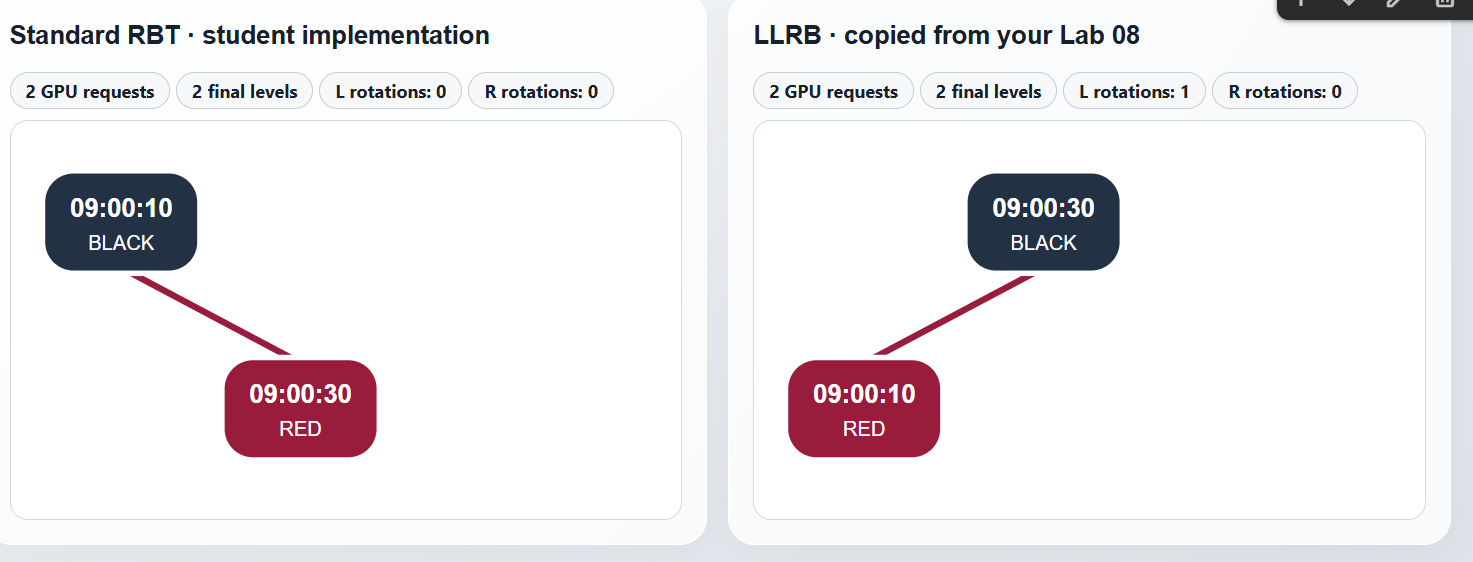

Short Explanation for Image 1:

The initial tree state after loading the first two requests (09:00:10 and 09:00:30), showing both the Standard RB Tree and the LLRB Tree side-by-side before any rebalancing or rotations occur.

**Your answer:**
Both trees maintain a simple binary search tree structure with two nodes. The Standard tree permits a red right link, whereas the LLRB tree strictly enforces the left-leaning property, resulting in different color assignments for the nodes while preserving the correct time order.


### 2. How do the rotations differ for the same new request?

Continue from Question 1. Set **When = 09:00:20**, **Student = Alice**, and click
**Add request** once. Inspect the trace for this insertion in each tree.

Record rotation directions and pivots **in order, for this insertion only**.
Explain why the two trees use different orders, then compare their root and
child colors after the insertion is complete. Use a small table:

| Tree | Rotations while adding 09:00:20, in order | Final root/color | Final child colors |
| Standard | rotate_right(09:00:30) | 09:00:20 / BLACK | Left: 09:00:10 (RED), Right: 09:00:30 (RED) |
| LLRB | rotate_right(09:00:30), rotate_left(09:00:10) | 09:00:20 / BLACK | Left: 09:00:10 (black), Right: 09:00:30(black) |

**Image 2:** select Trace **Standard** and find `ROTATE_RIGHT_AFTER` for request
09:00:20: the state immediately after its first rotation. Capture the Standard panel.
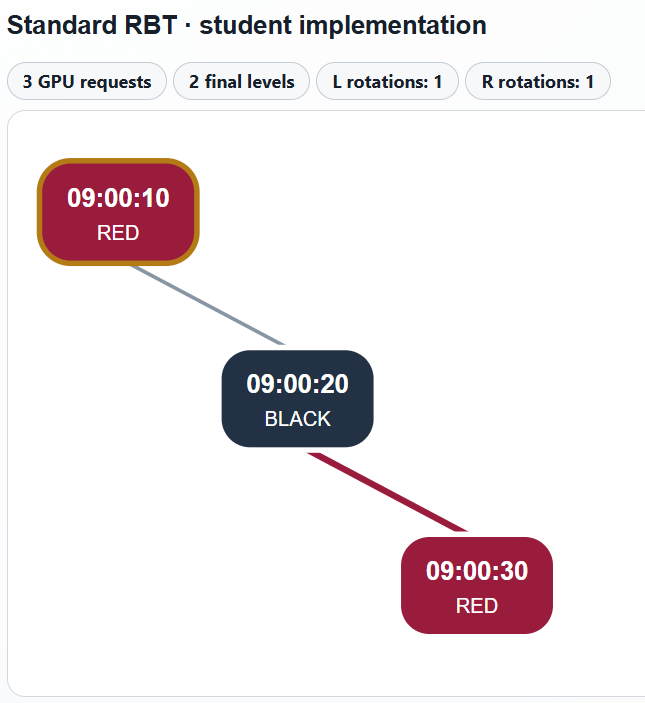

**Image 3:** select Trace **LLRB** and find `ROTATE_LEFT_AFTER` for request
09:00:20: the state immediately after its first rotation. Capture the LLRB panel.
Do not use the earlier left rotation for request 09:00:30.

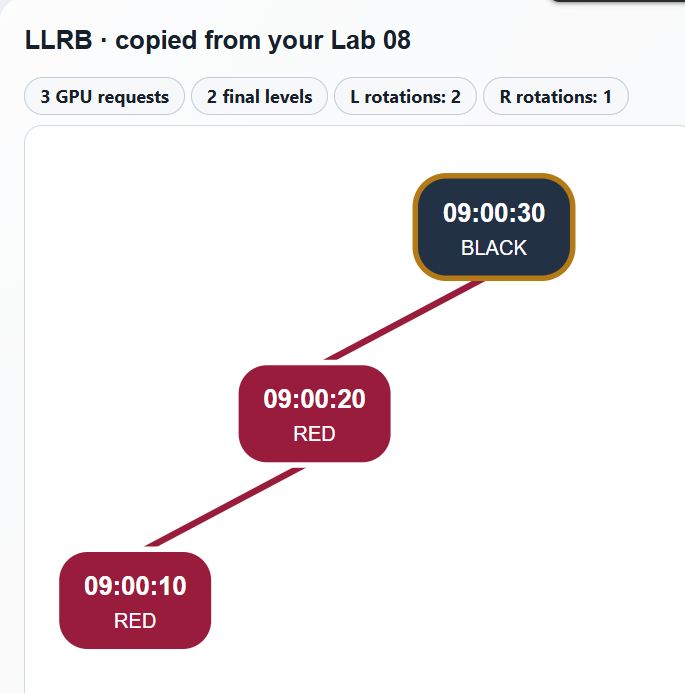

**Image 4:** click **Final tree** and capture both completed trees in one image.
Intermediate states can violate RB rules; compare final validity after COMMIT.
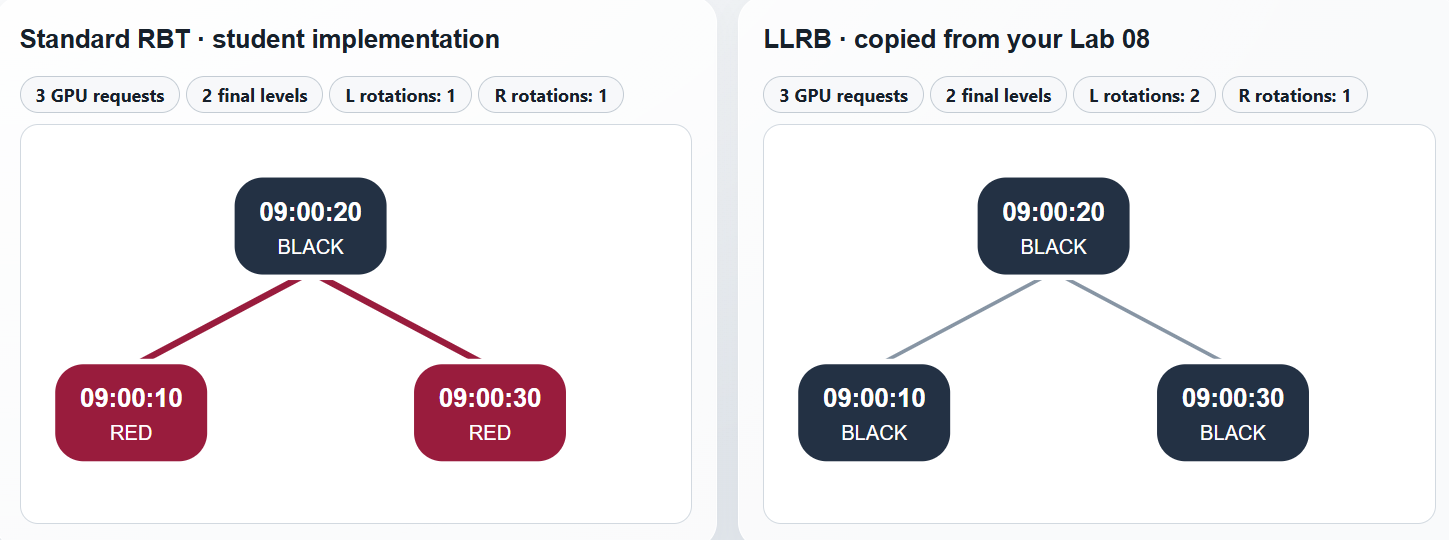

**Your answer:**
Inserting 09:00:20 triggers a structural rebalancing. The Standard tree performs standard rotations and color adjustments (such as handling uncle/parent relations), while the LLRB tree maintains its balance specifically through single rotations and color flips to ensure all red links lean left.


### 3. When do the two trees need different repairs?

Continue from the final trees in Question 2. Add **When = 09:00:05**, **Student = Ben**.

Using the colors before insertion, explain which tree needs recoloring or
rotation, and which needs no repair. Check your explanation with the trace
for **09:00:05 only**. Why can the two final pictures now agree even though
the repair histories differ?

**Image 5:** click **Final tree** and capture both completed trees. Use Image 4
as the before-state; do not submit another copy of it. Write one short explanation.

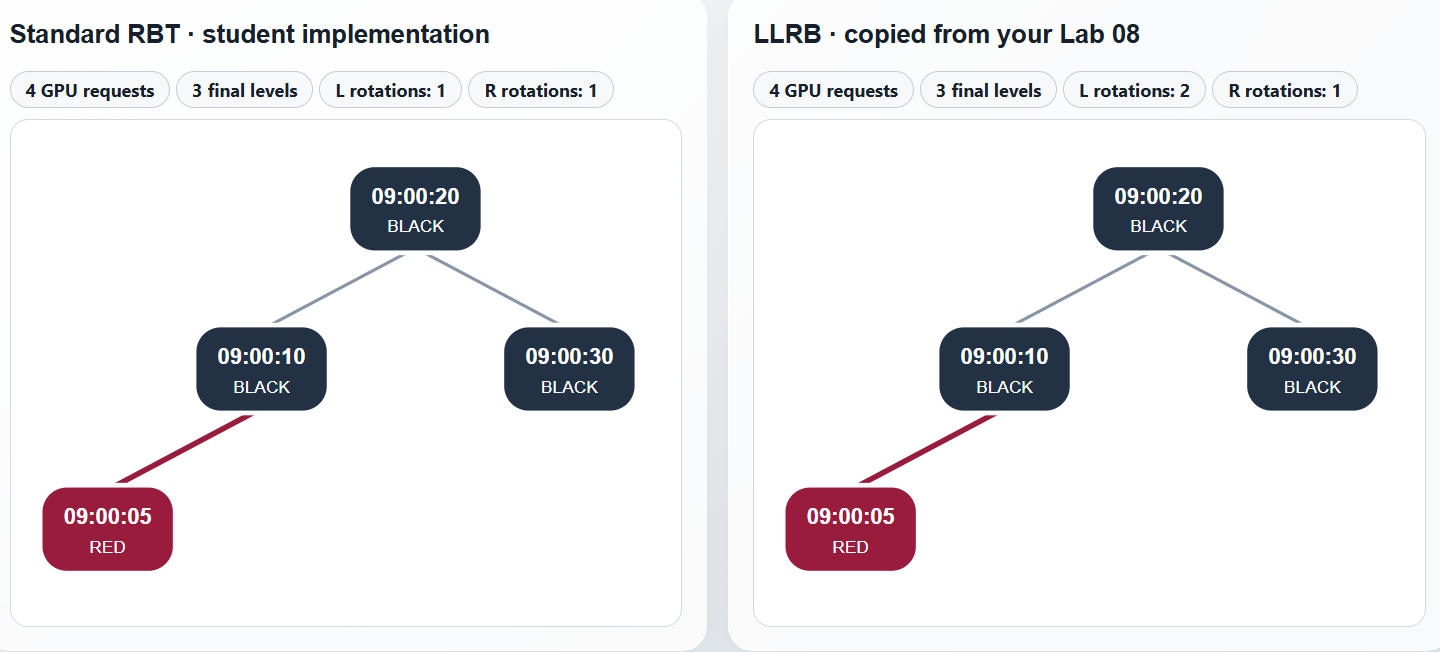

**Your answer:**

Inserting the oldest timestamp (09:00:05) causes a cascade of rebalancing operations up to the root in both trees. Although their internal rotation mechanics differ (Standard allowing right red links vs. LLRB maintaining strict left-leaning rules), both trees successfully reach a valid red-black balanced state with the correct in-order traversal of all four GPU requests.

## Submit

Submit one notebook containing your copied LLRB bodies, the seven reused
Standard bodies, four new Standard bodies, executed **ALL CHECKS PASSED**, answers to **Questions 1–3**, and
**exactly five images**, numbered 1–5 and placed below the matching answers.
Distribution: **Question 1: one; Question 2: three; Question 3: one**.
Keep both classes and the app so the instructor can reproduce your results.
No additional screenshots are required for checks, lookups, or other presets.